In [37]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler

# 读取数据
province_df = pd.read_csv('/home/mw/input/data_total74037403/地区角度数据集/province.csv')

feature_cols = ['显卡进口数量', '人工智能区域竞争力指数', '人工智能企业数']

def critic_weight(data):
    scaler = MinMaxScaler(feature_range=(0.001, 1))
    data_std = scaler.fit_transform(data)
    std = np.std(data_std, axis=0, ddof=1)
    corr = np.corrcoef(data_std, rowvar=False)
    conflict = 1 - np.abs(corr)
    info = std * np.sum(conflict, axis=1)
    weights = info / np.sum(info)
    return weights

def calculate_scores(data, weights):
    scaler = MinMaxScaler(feature_range=(0.001, 1))
    data_std = scaler.fit_transform(data)
    scores = np.sum(data_std * weights, axis=1)
    return scores

def gini(array):
    array = np.sort(array)
    n = len(array)
    cum = np.cumsum(array)
    return (n + 1 - 2 * np.sum(cum) / cum[-1]) / n

# 逐年处理
results = []
for year in sorted(province_df['年份'].unique()):
    year_data = province_df[province_df['年份'] == year]
    data = year_data[feature_cols].values
    weights = critic_weight(data)
    scores = calculate_scores(data, weights)
    gini_coef = gini(scores)
    results.append({
        '年份': year,
        '权重': dict(zip(feature_cols, weights)),
        '得分': dict(zip(year_data['省份'], scores)),
        '基尼系数': gini_coef
    })

# 输出权重和基尼系数
weights_df = pd.DataFrame([{**{'年份': r['年份']}, **r['权重']} for r in results])
gini_df = pd.DataFrame([(r['年份'], r['基尼系数']) for r in results], columns=['年份', '基尼系数'])

print("各年CRITIC权重：")
print(weights_df.set_index('年份'))
print("\n各年基尼系数：")
print(gini_df.set_index('年份'))

# 各省每年得分
scores_list = []
for r in results:
    for prov, score in r['得分'].items():
        scores_list.append({'年份': r['年份'], '省份': prov, '得分': score})
scores_df = pd.DataFrame(scores_list)
print("\n各省每年得分：")
print(scores_df)

weights_df.to_csv('地区权重.csv', index=False, encoding='utf-8-sig')
gini_df.to_csv('地区基尼系数.csv', index=False, encoding='utf-8-sig')
scores_df.to_csv('地区评分.csv', index=False, encoding='utf-8-sig')

各年CRITIC权重：
        显卡进口数量  人工智能区域竞争力指数   人工智能企业数
年份                                   
2019  0.327254     0.420711  0.252035
2020  0.339963     0.384251  0.275786
2021  0.340827     0.375361  0.283812
2022  0.467240     0.300845  0.231916
2023  0.426293     0.336668  0.237040

各年基尼系数：
          基尼系数
年份            
2019  0.604106
2020  0.575735
2021  0.556228
2022  0.589310
2023  0.577850

各省每年得分：
       年份        省份        得分
0    2019       安徽省  0.083538
1    2019        北京  0.505098
2    2019       福建省  0.121395
3    2019       甘肃省  0.022756
4    2019       广东省  0.779359
..    ...       ...       ...
150  2023     西藏自治区  0.001000
151  2023  新疆维吾尔自治区  0.024804
152  2023       云南省  0.137193
153  2023       浙江省  0.255222
154  2023       重庆市  0.090298

[155 rows x 3 columns]


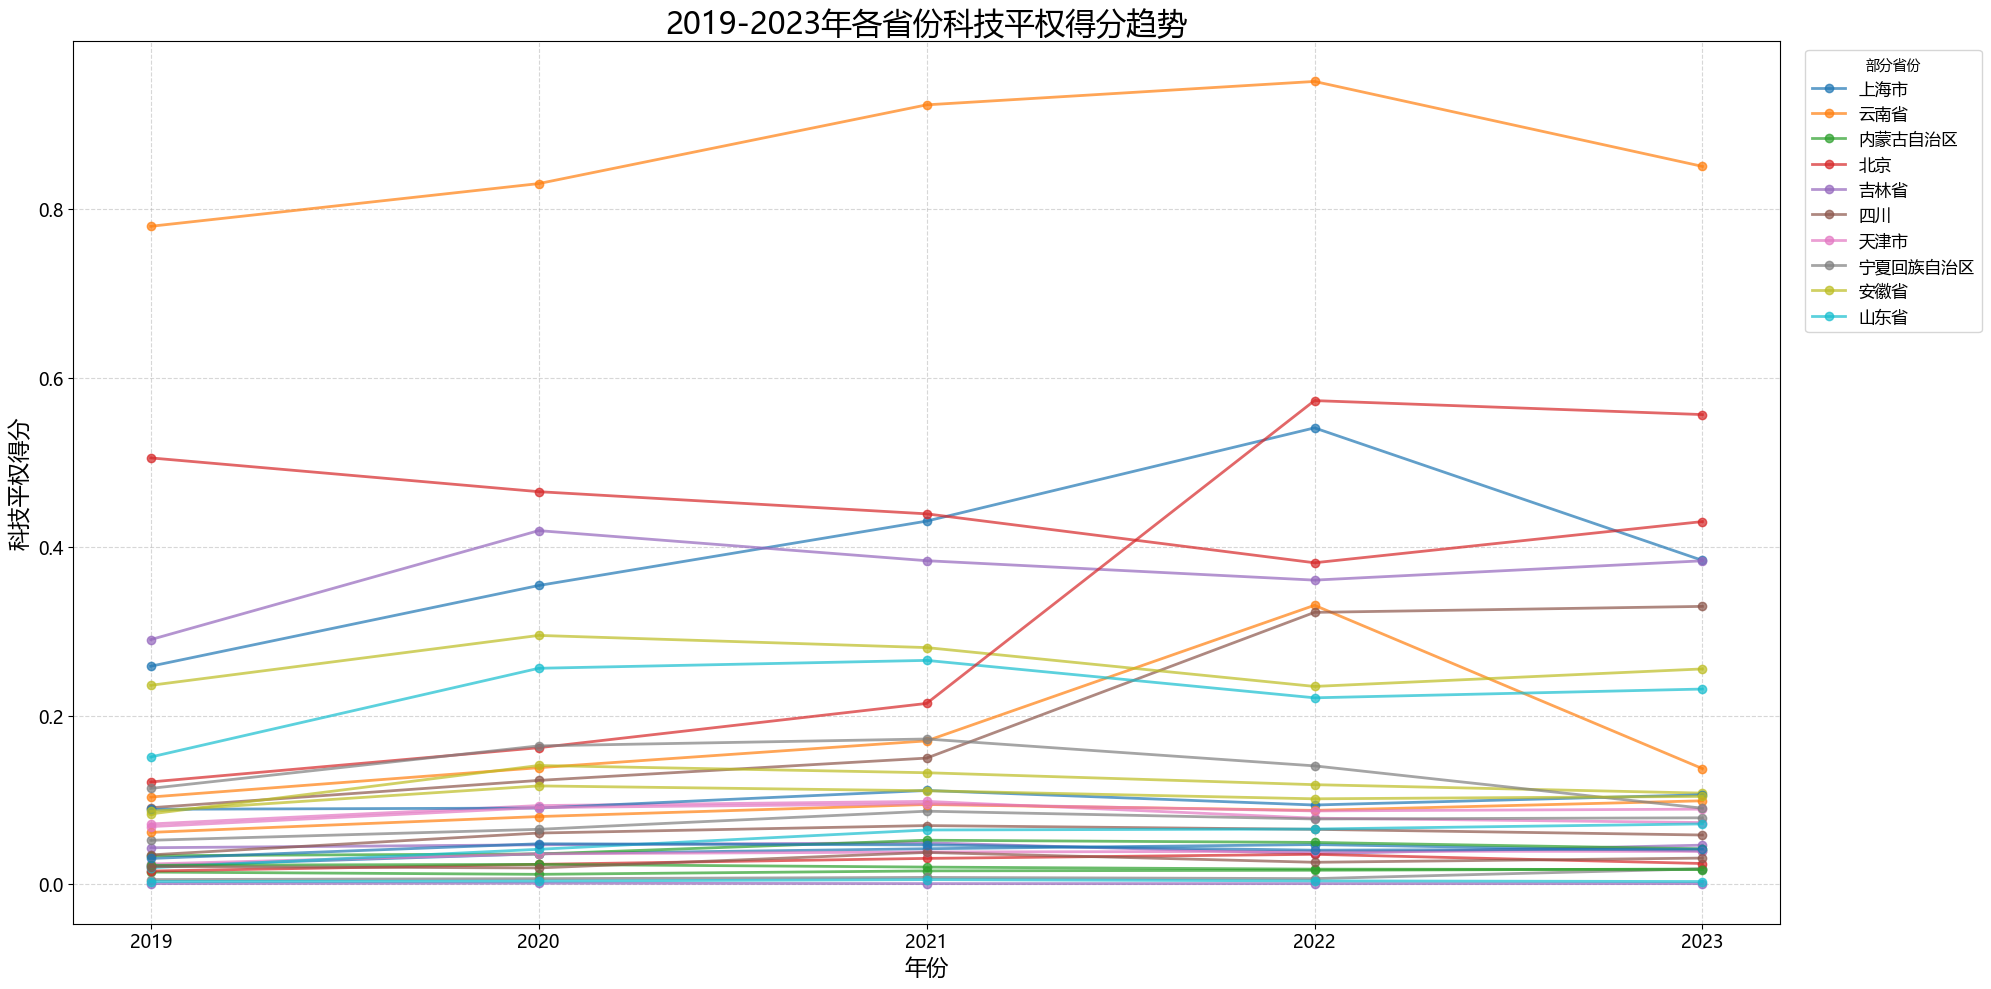

In [39]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib

# 设置全局字体为微软雅黑
matplotlib.rcParams['font.sans-serif'] = ['Microsoft YaHei']
matplotlib.rcParams['axes.unicode_minus'] = False

# 读取得分数据
scores_df = pd.read_csv('/home/mw/input/data_total74037403/地区角度数据集/地区评分.csv')

# 透视表，行是省份，列是年份，值是得分
pivot_df = scores_df.pivot(index='省份', columns='年份', values='得分')

plt.figure(figsize=(18, 10))
for prov in pivot_df.index:
    plt.plot(pivot_df.columns, pivot_df.loc[prov], marker='o', linewidth=2, alpha=0.7)

plt.title('2019-2023年各省份科技平权得分趋势', fontsize=22)
plt.xlabel('年份', fontsize=16)
plt.ylabel('科技平权得分', fontsize=16)
plt.xticks(pivot_df.columns, fontsize=13)
plt.yticks(fontsize=13)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

# 只显示部分省份图例，避免过多
handles, labels = plt.gca().get_legend_handles_labels()
plt.legend(pivot_df.index[:10], title='部分省份', bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=12)

plt.show()

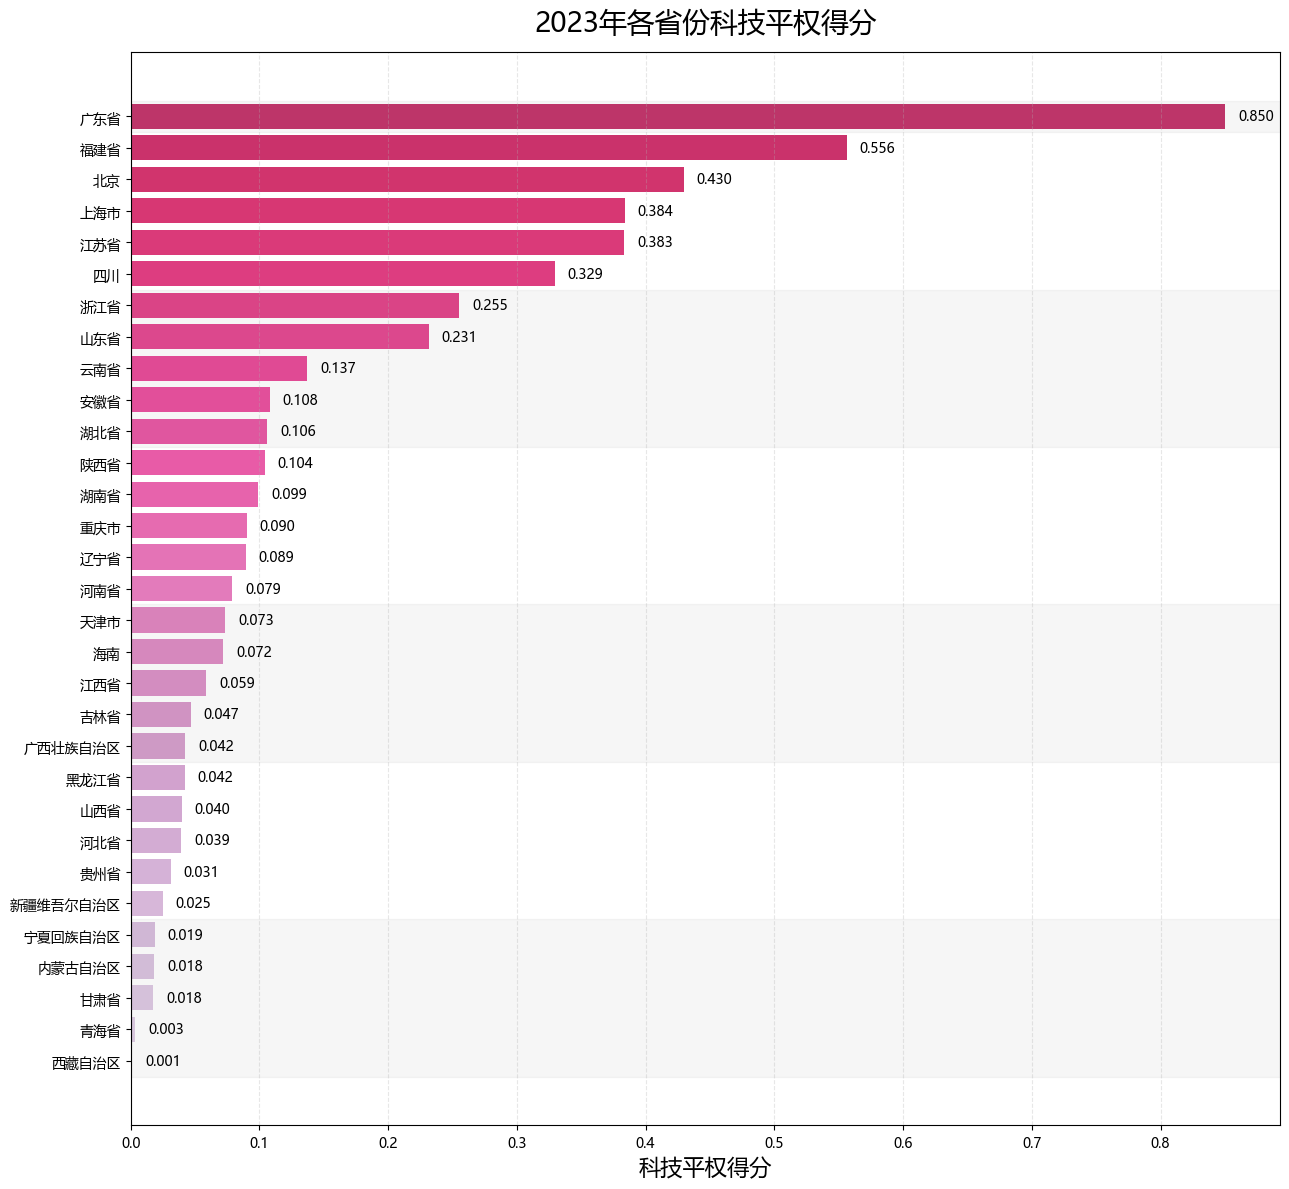

In [38]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

matplotlib.rcParams['font.sans-serif'] = ['Microsoft YaHei']
matplotlib.rcParams['axes.unicode_minus'] = False

scores_df = pd.read_csv('/home/mw/input/data_total74037403/地区角度数据集/地区评分.csv')
scores_2023 = scores_df[scores_df['年份'] == 2023].sort_values('得分', ascending=True)

plt.figure(figsize=(13, 12))
bars = plt.barh(scores_2023['省份'], scores_2023['得分'], color=plt.cm.PuRd(np.linspace(0.2, 0.8, len(scores_2023))), alpha=0.85)
plt.xlabel('科技平权得分', fontsize=16)
plt.title('2023年各省份科技平权得分', fontsize=20, pad=15)
plt.grid(axis='x', linestyle='--', alpha=0.3)

# 添加分区色块背景
for i in range(0, len(scores_2023), 5):
    plt.axhspan(i-0.5, min(i+4.5, len(scores_2023)-0.5), color='gray', alpha=0.07 if i//5%2==0 else 0)

for bar, score in zip(bars, scores_2023['得分']):
    plt.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height()/2, f'{score:.3f}', va='center', fontsize=10)
plt.tight_layout()
plt.show()

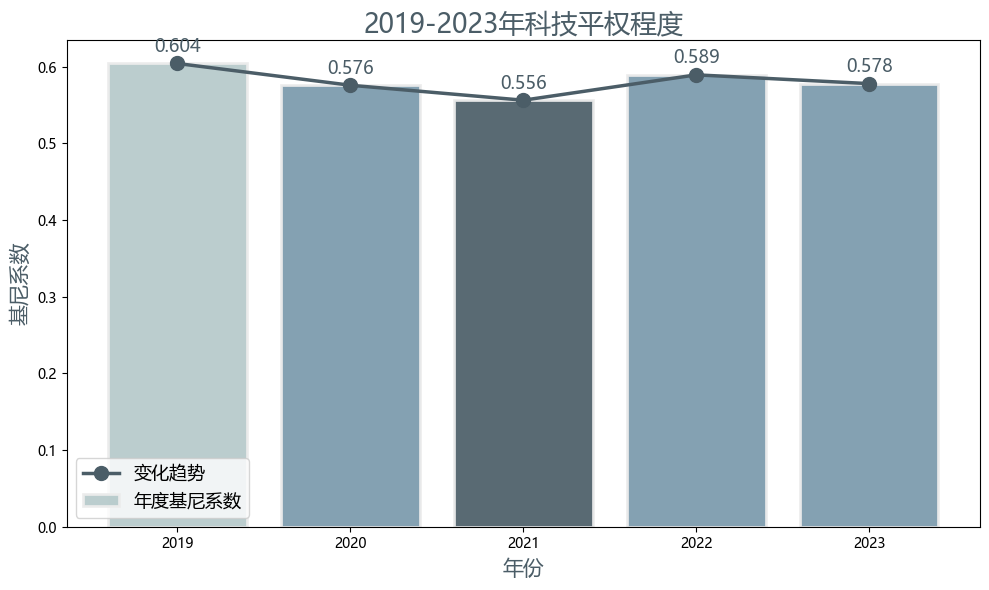

In [34]:
import pandas as pd
import matplotlib.pyplot as plt

matplotlib.rcParams['font.sans-serif'] = ['Microsoft YaHei']
matplotlib.rcParams['axes.unicode_minus'] = False

gini_df = pd.read_csv('/home/mw/input/data_total74037403/地区角度数据集/gini.csv')
main_color = '#7A99AC'
highlight_max = '#B5C9CA'
highlight_min = '#4B5D67'
colors = [highlight_max if v==gini_df['gini'].max() else highlight_min if v==gini_df['gini'].min() else main_color for v in gini_df['gini']]

plt.figure(figsize=(10, 6))
bars = plt.bar(gini_df['year'].astype(str), gini_df['gini'], color=colors, alpha=0.92, edgecolor='#ECECEC', linewidth=2, zorder=1, label='年度基尼系数')
line, = plt.plot(gini_df['year'].astype(str), gini_df['gini'], color='#4B5D67', marker='o', linewidth=2.5, markersize=10, zorder=2, label='变化趋势')
for bar, y in zip(bars, gini_df['gini']):
    plt.text(bar.get_x() + bar.get_width()/2, y + 0.01, f'{y:.3f}', ha='center', va='bottom', fontsize=13, color='#4B5D67')
plt.title('2019-2023年科技平权程度', fontsize=19, color='#4B5D67')
plt.xlabel('年份', fontsize=15, color='#4B5D67')
plt.ylabel('基尼系数', fontsize=15, color='#4B5D67')
plt.legend(fontsize=13, loc='best')  
plt.tight_layout()
plt.show()